In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import(
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    f1_score,
    roc_auc_score,
    classification_report,
    RocCurveDisplay
)

In [5]:
df=pd.read_csv("/content/PhiUSIIL_Phishing_URL_Dataset.csv")

In [6]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24.0,0.0,com,100.0,1.000000,0.522907,...,0.0,0.0,1.0,34.0,20.0,28.0,119.0,0.0,124.0,1.0
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16.0,0.0,de,100.0,0.666667,0.032650,...,0.0,0.0,1.0,50.0,9.0,8.0,39.0,0.0,217.0,1.0
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22.0,0.0,uk,100.0,0.866667,0.028555,...,0.0,0.0,1.0,10.0,2.0,7.0,42.0,2.0,5.0,1.0
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19.0,0.0,com,100.0,1.000000,0.522907,...,1.0,1.0,1.0,3.0,27.0,15.0,22.0,1.0,31.0,1.0
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26.0,0.0,org,100.0,1.000000,0.079963,...,1.0,0.0,1.0,244.0,15.0,34.0,72.0,1.0,85.0,1.0


In [7]:
df.shape


(161147, 56)

In [8]:
df.columns.tolist()

['FILENAME',
 'URL',
 'URLLength',
 'Domain',
 'DomainLength',
 'IsDomainIP',
 'TLD',
 'URLSimilarityIndex',
 'CharContinuationRate',
 'TLDLegitimateProb',
 'URLCharProb',
 'TLDLength',
 'NoOfSubDomain',
 'HasObfuscation',
 'NoOfObfuscatedChar',
 'ObfuscationRatio',
 'NoOfLettersInURL',
 'LetterRatioInURL',
 'NoOfDegitsInURL',
 'DegitRatioInURL',
 'NoOfEqualsInURL',
 'NoOfQMarkInURL',
 'NoOfAmpersandInURL',
 'NoOfOtherSpecialCharsInURL',
 'SpacialCharRatioInURL',
 'IsHTTPS',
 'LineOfCode',
 'LargestLineLength',
 'HasTitle',
 'Title',
 'DomainTitleMatchScore',
 'URLTitleMatchScore',
 'HasFavicon',
 'Robots',
 'IsResponsive',
 'NoOfURLRedirect',
 'NoOfSelfRedirect',
 'HasDescription',
 'NoOfPopup',
 'NoOfiFrame',
 'HasExternalFormSubmit',
 'HasSocialNet',
 'HasSubmitButton',
 'HasHiddenFields',
 'HasPasswordField',
 'Bank',
 'Pay',
 'Crypto',
 'HasCopyrightInfo',
 'NoOfImage',
 'NoOfCSS',
 'NoOfJS',
 'NoOfSelfRef',
 'NoOfEmptyRef',
 'NoOfExternalRef',
 'label']

In [9]:
df.isnull().sum().sum()

np.int64(52)

In [10]:
df["label"].value_counts()

,count
label,
1.0,92364
0.0,68782


In [11]:
df=df.dropna(subset=["label"]).copy()

In [12]:
y=(df["label"]==0).astype(int)

In [13]:
X=df.drop(
    columns=["label","URL","Domain","TLD","Title"],
    errors="ignore"
)

In [14]:
X=X.select_dtypes(include=np.number).copy()

In [15]:
X=X.replace([np.inf,-np.inf], np.nan)
X=X.fillna(X.median())
print("\nFeatures:", X.shape)
print("Target Distribution:")
print(y.value_counts())


Features: (161146, 50)
Target Distribution:
label
0    92364
1    68782
Name: count, dtype: int64



Training Samples: 128916
Testing Samples: 32230
[1 0 0 0 0 1 1 0 0 1]
[1 0 0 0 0 1 1 0 0 1]
[[18473     0]
 [    4 13753]]


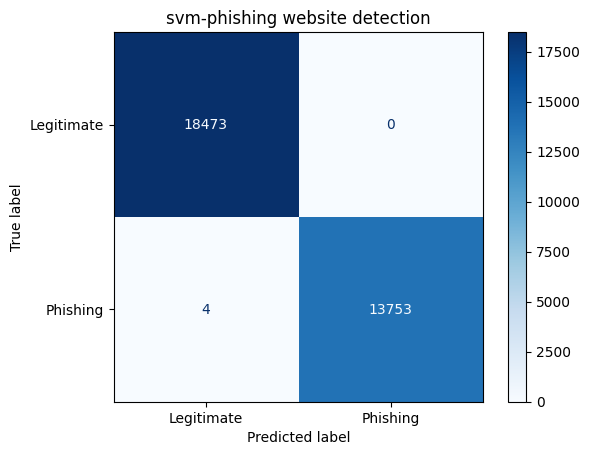

NameError: name 'roc_aue_score' is not defined

In [26]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))
model=make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
)
model.fit(X_train,y_train)

y_pred=model.predict(X_test)
y_score=model.decision_function(X_test)
print(y_test.iloc[:10].values)
print(y_pred[:10])
cm=confusion_matrix(
    y_test,
    y_pred,
    labels=[0,1]
)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate","Phishing"]
).plot(cmap="Blues",values_format="d")
plt.title("svm-phishing website detection")
plt.show()

precision=precision_score(
    y_test,y_pred,zero_division=0
)

f1=f1_score(
    y_test,y_pred,zero_division=0
)
roc_aue=roc_aue_score(y_test,y_score)
print("\n Model Performance")
print(f"Precision :{precision:.4f}")
print(f"Recall :{recall:.4f}")
print(f"F1-Score :{f1:.4f}")
print(f"ROC-Auc :{roc_auc:.4f}")
print("\nClassification Report:")
print(
    Classification_report(
        y_test,
        y_pred,
        labels=[0,1],
        target_names=["Legimate","phishing"],
        zero_division=0
    )
)
RocCurveDisplay.from_predictions(
    y_test,
    y_score,
    name="Linear SVM"
)
plt.plot([0,1],[0,1],"k--")
plt.title("ROC Curve-Svm Phishing Detection")
plt.show()

precision=precision_score(
    y_test,y_pred,zero_division=0
)

f1=f1_score(
    y_test,y_pred,zero_division=0
)
roc_aue=roc_aue_score(y_test,y_score)
print("\n Model Performance")
print(f"Precision :{precision:.4f}")
print(f"Recall :{recall:.4f}")
print(f"F1-Score :{f1:.4f}")
print(f"ROC-Auc :{roc_auc:.4f}")
print("\nClassification Report:")
print(
    Classification_report(
        y_test,
        y_pred,
        labels=[0,1],
        target_names=["Legimate","phishing"],
        zero_division=0
    )
)
RowCurveDisplay.from_Predictions(
    y_test,
    y_score,
    name="Linear SVM"
)
plt.plot([0,1],[0,1],"k--")
plt.title("ROC Curve-SVM Phishing Detection")
plt.show()